
# Advanced Techniques in Python Data Visualization

**Level:** Middle  
**Tools:** Python, Matplotlib, Seaborn  

---
## Assignment Objectives
1. Improve readability and aesthetics using Matplotlib & Seaborn.
2. Use fills to emphasize areas or comparisons.
3. Apply discrete and continuous color mapping correctly.
4. Use facet and grid for subgroup comparison.


In [ ]:

# Setup & Library Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)



## Dataset Loading

Use **Seaborn built-in datasets**.  
You may use one or more datasets below:

- tips
- penguins
- flights

Example loading:
```python
df = sns.load_dataset("tips")
```


In [ ]:
import pandas as pd
import seaborn as sns

# Load dataset
df = sns.load_dataset("tips")

# Set display options
pd.set_option("display.max_rows", 10)
pd.set_option("display.max_columns", None)

# Display dataset
df


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [ ]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



## Task 1 — Readability & Aesthetic Improvement

### Goal
Compare a default plot vs an improved plot in terms of readability and aesthetics.


In [ ]:

# TODO:
# 1. Choose one numeric and one categorical variable
# 2. Create a basic plot with default settings (no customization)
# 3. Recreate the SAME plot with:
#    - Proper title
#    - Axis labels
#    - Adjusted font size
#    - Improved color choice
#    - Grid or theme adjustment
#
# Hint: Use plt.subplots() or sns.set_theme()


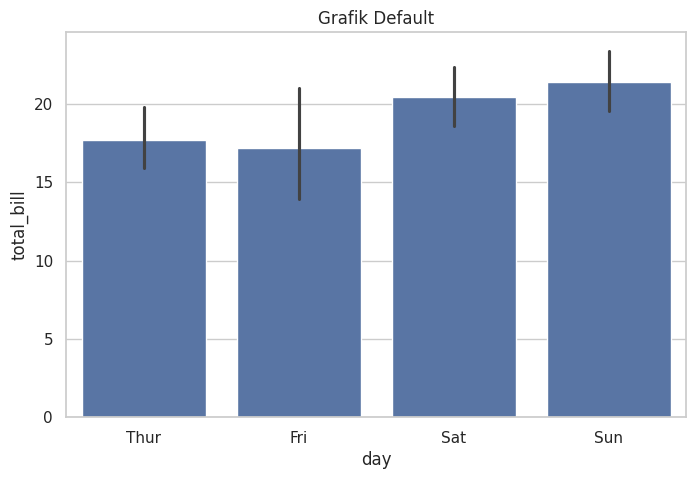

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="day",
    y="total_bill"
)

plt.title("Grafik Default")
plt.show()

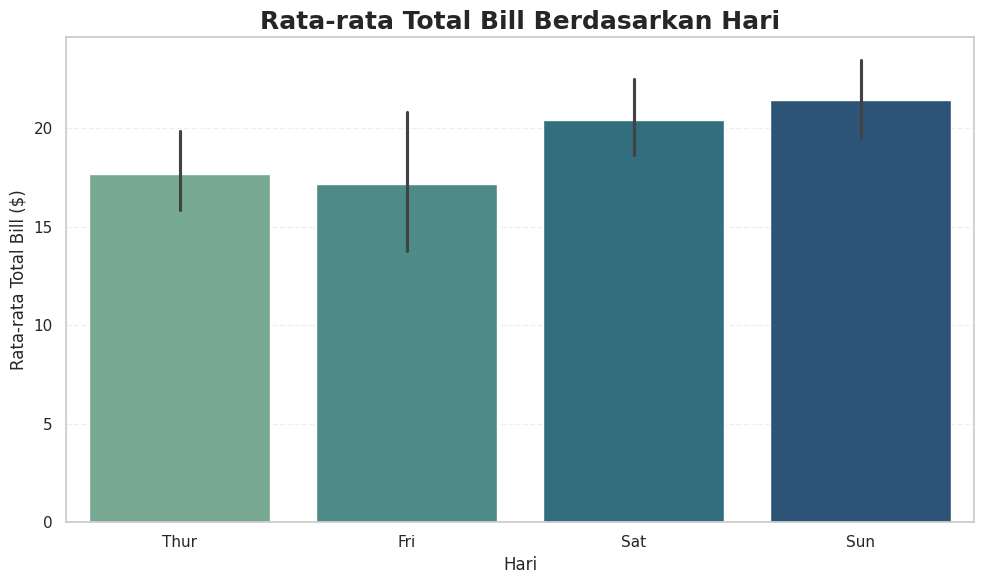

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df,
    x="day",
    y="total_bill",
    hue="day",
    palette="crest",
    legend=False
)

plt.title(
    "Rata-rata Total Bill Berdasarkan Hari",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Hari")
plt.ylabel("Rata-rata Total Bill ($)")

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.show()


### Questions
1. What visual elements did you change to improve readability?
2. Which changes had the biggest impact and why?


**Analisis**

Visualisasi ditingkatkan dengan menambahkan judul yang informatif, label sumbu yang jelas, palet warna crest, serta grid agar grafik lebih mudah dibaca dan terlihat profesional.

**Reflection Questions**
1. Elemen visual apa yang diubah untuk meningkatkan keterbacaan?

Jawaban:

Perubahan yang dilakukan meliputi penambahan judul grafik, label sumbu X dan Y, penggunaan palet warna crest yang lebih modern, penambahan grid horizontal, serta pengaturan ukuran font agar informasi lebih mudah dibaca dan dipahami.

2. Perubahan mana yang paling memberikan dampak? Mengapa?

Jawaban:

Perubahan yang paling berdampak adalah penggunaan judul yang jelas, label sumbu, dan warna yang konsisten. Ketiga elemen tersebut membantu pembaca memahami isi grafik dengan lebih cepat tanpa harus melihat data mentah.


## Task 2 — Using Fills to Emphasize Data

### Goal
Use filled areas to emphasize comparison or distribution.


In [ ]:

# TODO:
# Choose ONE approach:
#
# Option A: Use plt.fill_between()
#   1. Aggregate numeric data if needed
#   2. Plot line + filled area
#
# Option B: Use area plot or stacked histogram
#   1. Compare distributions using fill
#   2. Ensure legend and labels are clear
#
# Explain briefly (markdown) what insight the fill helps highlight


In [ ]:
daily_bill = (
    df.groupby("day")["total_bill"]
      .mean()
      .reindex(["Thur","Fri","Sat","Sun"])
)

/tmp/ipykernel_2126/536984852.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("day")["total_bill"]


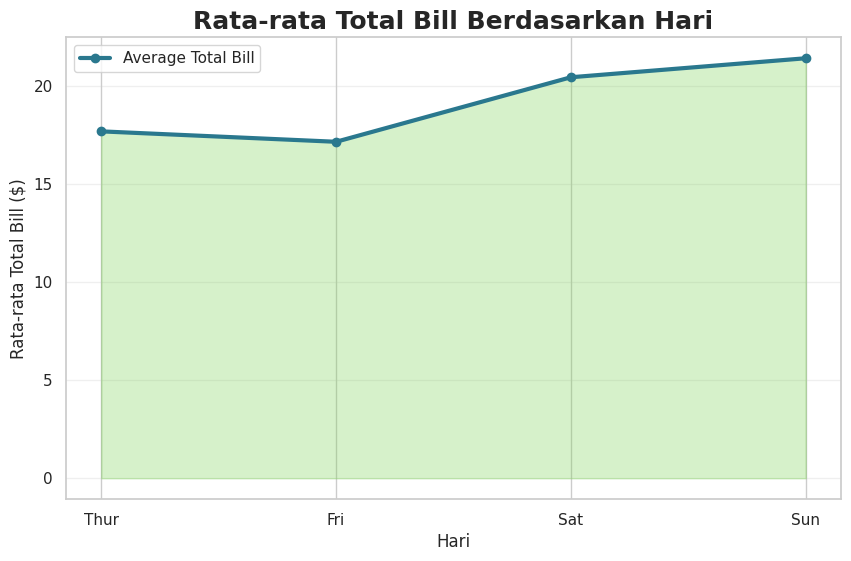

In [ ]:
plt.figure(figsize=(10,6))

x = range(len(daily_bill))

plt.plot(
    x,
    daily_bill.values,
    color="#2A788E",
    linewidth=3,
    marker="o",
    label="Average Total Bill"
)

plt.fill_between(
    x,
    daily_bill.values,
    color="#7AD151",
    alpha=0.3
)

plt.xticks(x, daily_bill.index)

plt.title(
    "Rata-rata Total Bill Berdasarkan Hari",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Hari")
plt.ylabel("Rata-rata Total Bill ($)")

plt.grid(axis="y", alpha=0.3)

plt.legend()

plt.show()


### Questions
1. What additional insight becomes clearer by using fill?
2. When could using fill make a visualization misleading?


**Analisis**

Area berwarna (fill) digunakan untuk memperjelas besarnya rata-rata total bill pada setiap hari sehingga tren perubahan data menjadi lebih mudah diamati.

**Reflection Questions**
1. Informasi tambahan apa yang menjadi lebih jelas setelah menggunakan fill?

Jawaban:

Penggunaan area berwarna membuat besarnya nilai rata-rata total bill pada setiap hari menjadi lebih mudah dibandingkan. Selain itu, pola kenaikan dan penurunan nilai dapat terlihat lebih jelas dibandingkan hanya menggunakan garis.

2. Kapan penggunaan fill dapat membuat visualisasi menjadi menyesatkan?

Jawaban:

Visualisasi dapat menjadi menyesatkan apabila digunakan pada data yang tidak kontinu, sumbu Y tidak dimulai dari nol, atau area berwarna terlalu dominan sehingga memberikan kesan adanya perbedaan yang lebih besar dari kondisi sebenarnya.


## Task 3 — Discrete vs Continuous Color Mapping

### Goal
Apply color mapping based on data type.


In [ ]:

# TODO:
# Part A — Discrete Colors
# 1. Select a categorical variable
# 2. Apply a discrete color palette (e.g. Set2, tab10)
#
# Part B — Continuous Colors
# 1. Select a numeric variable
# 2. Apply a continuous colormap (e.g. viridis, plasma)
#
# Make sure color choice improves interpretation


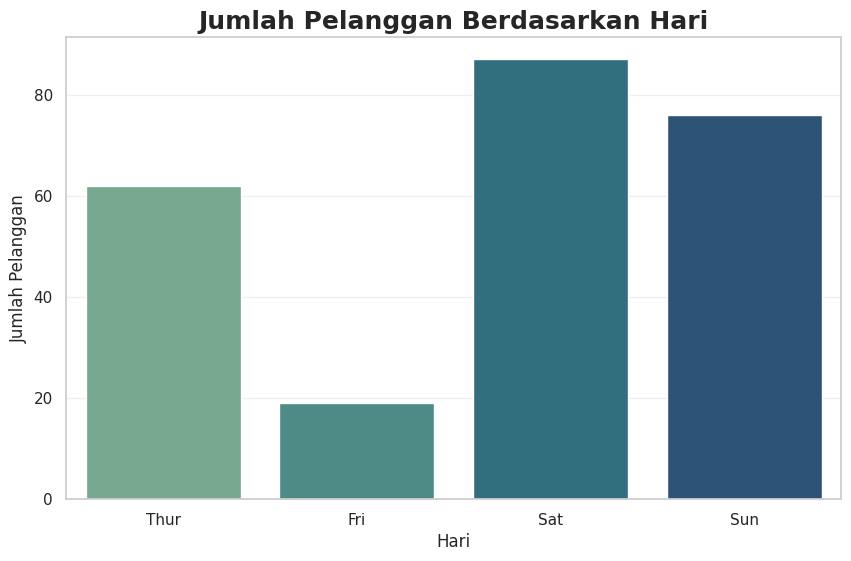

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="day",
    hue="day",
    palette="crest",
    legend=False
)

plt.title(
    "Jumlah Pelanggan Berdasarkan Hari",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Hari")
plt.ylabel("Jumlah Pelanggan")

plt.grid(axis="y", alpha=0.3)

plt.show()

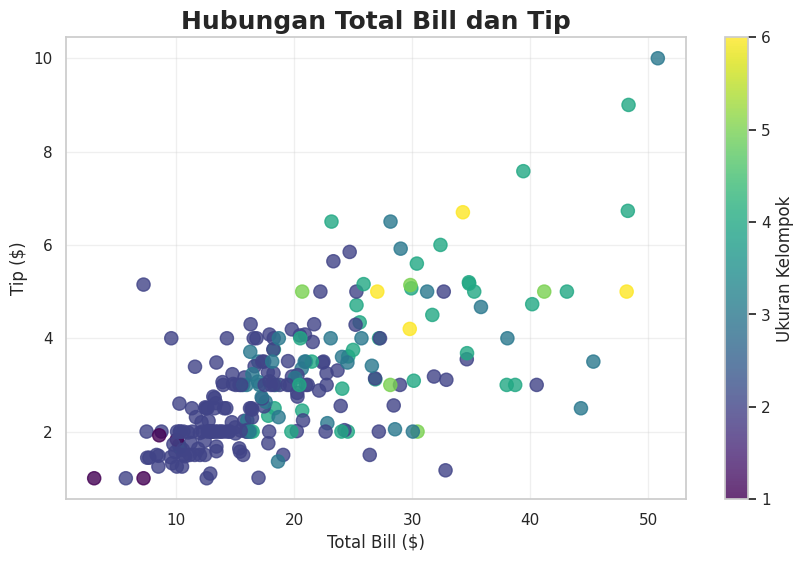

In [ ]:
plt.figure(figsize=(10,6))

scatter = plt.scatter(
    df["total_bill"],
    df["tip"],
    c=df["size"],
    cmap="viridis",
    s=90,
    alpha=0.8
)

plt.colorbar(
    scatter,
    label="Ukuran Kelompok"
)

plt.title(
    "Hubungan Total Bill dan Tip",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")

plt.grid(alpha=0.3)

plt.show()


### Questions
1. Why should categorical and numerical variables use different color strategies?
2. Mention one common mistake in color usage you avoided.


**Analisis**

Grafik pertama menggunakan warna diskrit karena variabel day merupakan data kategorikal. Grafik kedua menggunakan gradasi warna viridis karena variabel size merupakan data numerik sehingga lebih tepat ditampilkan dengan perubahan warna secara bertahap

**Reflection Questions**
1. Mengapa variabel kategorikal dan numerik harus menggunakan strategi warna yang berbeda?

Jawaban:

Variabel kategorikal menggunakan warna diskrit agar setiap kategori memiliki identitas warna yang berbeda dan mudah dikenali. Sebaliknya, variabel numerik menggunakan gradasi warna untuk menunjukkan perubahan nilai secara bertahap sehingga mempermudah interpretasi data.

2. Sebutkan satu kesalahan umum dalam penggunaan warna yang berhasil dihindari.

Jawaban:

Kesalahan yang dihindari adalah menggunakan gradasi warna pada data kategorikal. Hal tersebut dapat memberikan kesan adanya tingkatan atau urutan nilai, padahal kategori tersebut tidak memiliki hubungan numerik.


## Task 4 — Facet & Grid for Subgroup Comparison

### Goal
Compare multiple subgroups efficiently using facets.


In [ ]:

# TODO:
# 1. Select ONE numeric variable
# 2. Select TWO categorical grouping variables
# 3. Create faceted plots using ONE of:
#    - sns.FacetGrid
#    - sns.relplot()
#    - sns.catplot()
#
# Ensure:
# - Consistent axis scale
# - Clear titles
# - Readable facet labels


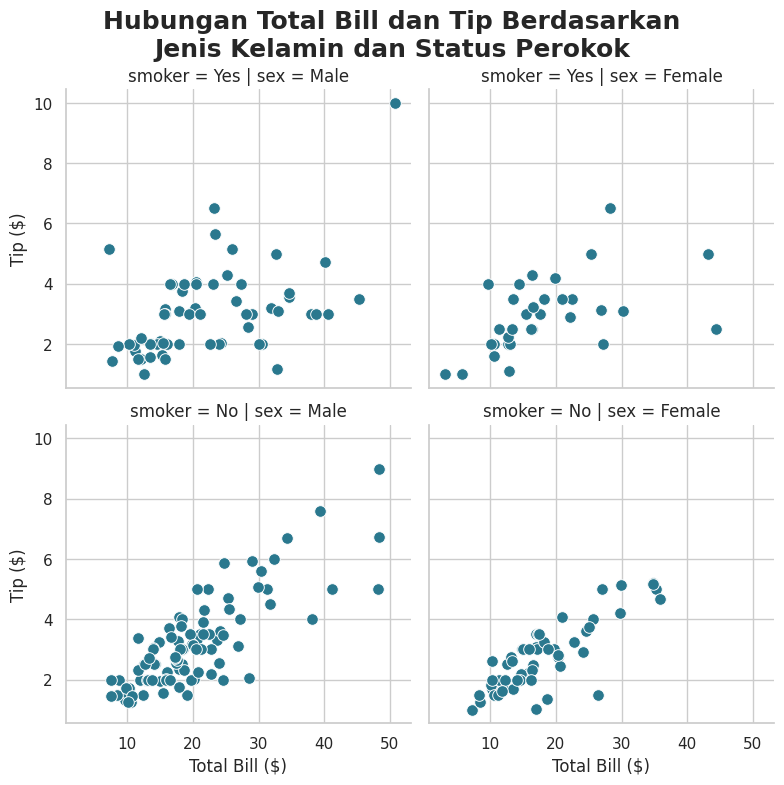

In [ ]:
g = sns.FacetGrid(
    df,
    row="smoker",
    col="sex",
    height=4
)

g.map_dataframe(
    sns.scatterplot,
    x="total_bill",
    y="tip",
    color="#2A788E",
    s=70
)

g.set_axis_labels(
    "Total Bill ($)",
    "Tip ($)"
)

g.fig.suptitle(
    "Hubungan Total Bill dan Tip Berdasarkan\nJenis Kelamin dan Status Perokok",
    fontsize=18,
    fontweight="bold"
)

g.fig.subplots_adjust(top=0.88)

plt.show()


### Questions
1. What insight is easier to identify using facet compared to a single plot?
2. What should you be careful about when interpreting faceted plots?


**Analisis**

Facet digunakan untuk membandingkan hubungan antara total bill dan tip berdasarkan jenis kelamin serta status perokok. Dengan memisahkan setiap kelompok ke dalam panel yang berbeda, pola data menjadi lebih mudah dibandingkan.

**Reflection Questions**
1. Informasi apa yang lebih mudah diidentifikasi menggunakan facet dibandingkan satu grafik?

Jawaban:

Facet memudahkan proses membandingkan hubungan antara total bill dan tip pada setiap kelompok pelanggan. Perbedaan pola antara pelanggan laki-laki dan perempuan maupun antara perokok dan bukan perokok dapat diamati dengan lebih jelas karena setiap kelompok ditampilkan secara terpisah.

2. Hal apa yang perlu diperhatikan ketika menginterpretasikan Faceted Plot?

Jawaban:

Saat menginterpretasikan Faceted Plot, perlu dipastikan bahwa semua panel menggunakan skala sumbu yang sama agar perbandingan antar kelompok tetap adil. Selain itu, jumlah data pada setiap kelompok juga perlu diperhatikan karena ukuran sampel yang berbeda dapat memengaruhi hasil interpretasi.


## Reflection

Answer briefly:
1. Which visualization technique helped you understand the data the most?
2. If this visualization were shown to non-technical stakeholders, what would you simplify?
3. Mention one visualization best practice you will consistently apply.


**Reflection**
1. Visualisasi mana yang paling membantu Anda memahami data?

Jawaban:

Visualisasi Facet Grid paling membantu saya memahami data karena memungkinkan perbandingan hubungan antara total bill dan tip berdasarkan jenis kelamin serta status perokok secara terpisah. Dengan cara ini, pola dan perbedaan antar kelompok menjadi lebih mudah diamati dibandingkan jika semua data ditampilkan dalam satu grafik.

2. Jika visualisasi ini ditampilkan kepada stakeholder non-teknis, apa yang akan Anda sederhanakan?

Jawaban:

Saya akan menyederhanakan visualisasi dengan mengurangi elemen yang kurang penting, menggunakan judul yang lebih mudah dipahami, mengganti istilah teknis dengan bahasa yang sederhana, serta menambahkan anotasi atau kesimpulan singkat pada grafik agar informasi utama dapat dipahami dengan cepat tanpa perlu memahami detail teknis.

3. Sebutkan satu praktik terbaik dalam visualisasi data yang akan selalu Anda terapkan.

Jawaban:

Salah satu praktik terbaik yang akan selalu saya terapkan adalah membuat visualisasi yang sederhana, konsisten, dan mudah dibaca, dengan memberikan judul yang informatif, label sumbu yang jelas, serta menggunakan warna yang sesuai agar informasi dapat dipahami dengan cepat dan tidak menimbulkan kesalahan interpretasi.